<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js14/TG14_2_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **JS14 - Convolutional Neural Network**
---
---
**PRAKTIKUM 2**

## Langkah 1 - Install & import library

In [1]:
!pip install -q kagglehub

In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)
pd.set_option("display.max_columns", 50)

## Langkah 2 - Load dataset dari Kaggle

In [3]:
dataset_dir = Path(kagglehub.dataset_download("abiyyurasyiq/jakarta-house-price-dataset"))
csv_files = sorted(dataset_dir.rglob("*.csv"))
print("File CSV:", [f.name for f in csv_files])

df = pd.read_csv(csv_files[0])
print("Bentuk data:", df.shape)

TARGET = None   # contoh manual: TARGET = "price_in_rp"
if TARGET is None:
    cands = [c for c in df.columns if re.search(r"price|harga", c, re.I)]
    print("Kandidat kolom harga:", cands)
    TARGET = cands[0]
print("Kolom harga dipakai:", TARGET)

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df.head()

Using Colab cache for faster access to the 'jakarta-house-price-dataset' dataset.
File CSV: ['jakarta_house.csv']
Bentuk data: (10000, 9)
Kandidat kolom harga: ['price']
Kolom harga dipakai: price


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


## Langkah 3 - Pembersihan data, split, dan pembentukan 5 kelas harga

In [4]:
data = df.drop_duplicates().copy()
data = data[data[TARGET].notna() & (data[TARGET] > 0)]

lo, hi = data[TARGET].quantile([0.01, 0.99])          # buang outlier ekstrem harga
data = data[(data[TARGET] >= lo) & (data[TARGET] <= hi)].reset_index(drop=True)
print("Jumlah data bersih:", len(data))

train_df, test_df = train_test_split(data, test_size=0.2, random_state=42)

class_names = ["sangat murah", "murah", "menengah", "mahal", "sangat mahal"]
train_cls, bins = pd.qcut(train_df[TARGET], q=5, labels=False, retbins=True, duplicates="drop")
bins[0], bins[-1] = -np.inf, np.inf
test_cls = pd.cut(test_df[TARGET], bins=bins, labels=False)

y_train = train_cls.astype(int).values
y_test = test_cls.astype(int).values

print("Batas harga antar kelas (Rp):")
for i in range(1, len(bins) - 1):
    print(f"  {class_names[i-1]} | {class_names[i]}: {bins[i]:,.0f}")

Jumlah data bersih: 9805
Batas harga antar kelas (Rp):
  sangat murah | murah: 2,200,000,000
  murah | menengah: 3,500,000,000
  menengah | mahal: 5,800,000,000
  mahal | sangat mahal: 12,000,000,000


## Langkah 4 - Pra-pengolahan fitur

In [5]:
MAX_CAT = 40

X_train_raw = train_df.drop(columns=[TARGET])
X_test_raw = test_df.drop(columns=[TARGET])

drop_cols = []
for c in X_train_raw.columns:
    col = X_train_raw[c]
    if re.search(r"(^|_)id$", c, re.I) or col.isna().mean() > 0.5:
        drop_cols.append(c)
    elif not pd.api.types.is_numeric_dtype(col) and col.nunique() > MAX_CAT:
        drop_cols.append(c)
    elif pd.api.types.is_numeric_dtype(col) and col.nunique() <= 1:
        drop_cols.append(c)
print("Kolom dibuang:", drop_cols)

X_train_raw = X_train_raw.drop(columns=drop_cols)
X_test_raw = X_test_raw.drop(columns=drop_cols)
cat_cols = [c for c in X_train_raw.columns if not pd.api.types.is_numeric_dtype(X_train_raw[c])]

X_train = pd.get_dummies(X_train_raw, columns=cat_cols, dtype=float)
X_test = pd.get_dummies(X_test_raw, columns=cat_cols, dtype=float).reindex(columns=X_train.columns, fill_value=0.0)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_c = X_train_s[..., np.newaxis]     # (sampel, fitur, 1)
X_test_c = X_test_s[..., np.newaxis]
print("X_train:", X_train_c.shape, "| X_test:", X_test_c.shape)

Kolom dibuang: ['district']
X_train: (7844, 11, 1) | X_test: (1961, 11, 1)


## Langkah 5 - Verifikasi data

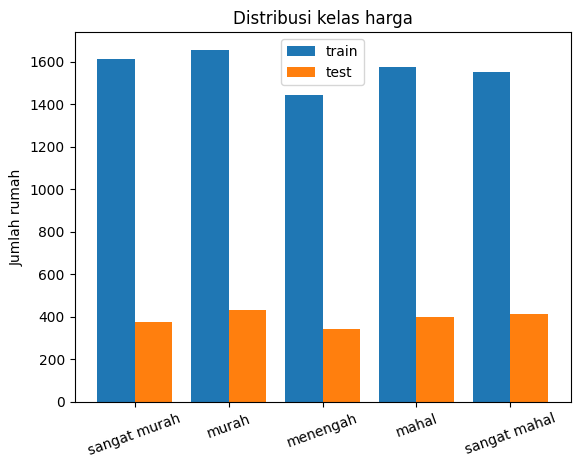

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
6625,6777,9500000000,Puri Indah,Jakarta Barat,3,2,2,336.0,600.0
6134,6277,1150000000,Cengkareng Barat,Jakarta Barat,2,2,1,50.0,70.0
6192,6336,1550000000,Pejaten Timur,Jakarta Selatan,3,3,0,65.0,114.0
9552,9742,2800000000,Taman Ratu,Jakarta Barat,3,3,2,90.0,134.0
4834,4962,12900000000,Pantai Indah Kapuk,Jakarta Utara,5,5,3,324.0,415.0


In [6]:
counts_tr = np.bincount(y_train, minlength=5)
counts_te = np.bincount(y_test, minlength=5)

x = np.arange(5)
plt.bar(x - 0.2, counts_tr, width=0.4, label="train")
plt.bar(x + 0.2, counts_te, width=0.4, label="test")
plt.xticks(x, class_names, rotation=20)
plt.ylabel("Jumlah rumah"); plt.title("Distribusi kelas harga"); plt.legend()
plt.show()

train_df.head()

## Langkah 6 - Membangun model CNN

### **6.1 Bagian konvolusi**
 tiga Conv1D (32 -> 64 -> 64 filter) dengan MaxPooling di antaranya.

In [7]:
n_features = X_train_c.shape[1]

model = models.Sequential([
    layers.Input(shape=(n_features, 1)),
    layers.Conv1D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding="same", activation="relu"),
])

### **6.2 Cek arsitektur bagian konvolusi**

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 11, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 2, 64)          │        12,352 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,688 (73.00 KB)

 Trainable params: 18,688 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

### **6.3 Tambahkan bagian klasifikasi**
Flatten, Dense 64 (ReLU), dan Dense 5 sebagai logits untuk 5 kelas.

In [9]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation="relu"))
model.add(layers.Dense(5))     # logits, tanpa softmax

### **6.4 Cek arsitektur lengkap**

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 11, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 2, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,269 (106.52 KB)

 Trainable params: 27,269 (106.52 KB)

 Non-trainable params: 0 (0.00 B)

### **6.5 Compile**

In [11]:
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

## Langkah 7 - Training (10 epoch)
20% data training dipakai sebagai validasi; data test tetap murni untuk evaluasi akhir.

In [12]:
history = model.fit(
    X_train_c, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
)

Epoch 1/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5315 - loss: 1.0636 - val_accuracy: 0.5889 - val_loss: 0.9334
Epoch 2/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6166 - loss: 0.8714 - val_accuracy: 0.6150 - val_loss: 0.8776
Epoch 3/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6279 - loss: 0.8447 - val_accuracy: 0.6233 - val_loss: 0.8503
Epoch 4/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6354 - loss: 0.8283 - val_accuracy: 0.6291 - val_loss: 0.8390
Epoch 5/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6375 - loss: 0.8176 - val_accuracy: 0.6342 - val_loss: 0.8328
Epoch 6/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6438 - loss: 0.8082 - val_accuracy: 0.6361 - val_loss: 0.8262
Epoch 7/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6443 - loss: 0.8001 - val_accuracy: 0.6342 - val_loss: 0.8185
Epoch 8/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6462 - loss: 0.7942 - val_accuracy: 0

## Langkah 8 - Evaluasi model (grafik akurasi)

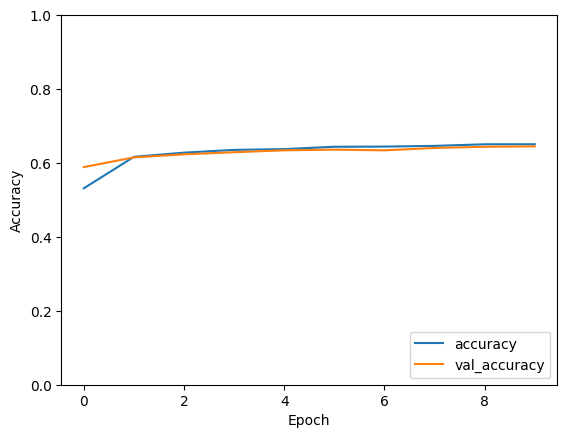

62/62 - 0s - 3ms/step - accuracy: 0.6502 - loss: 0.7967


In [13]:
plt.plot(history.history["accuracy"], label="accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0, 1])
plt.legend(loc="lower right")
plt.show()

test_loss, test_acc = model.evaluate(X_test_c, y_test, verbose=2)

## Langkah 9 - Cetak akurasi

In [14]:
print(f"Akurasi data test: {test_acc:.4f} ({test_acc*100:.2f}%)")

Akurasi data test: 0.6502 (65.02%)


## Tambahan - Confusion matrix & contoh prediksi

              precision    recall  f1-score   support

sangat murah       0.82      0.73      0.77       375
       murah       0.58      0.68      0.62       432
    menengah       0.44      0.51      0.47       342
       mahal       0.61      0.51      0.56       400
sangat mahal       0.84      0.80      0.82       412

    accuracy                           0.65      1961
   macro avg       0.66      0.65      0.65      1961
weighted avg       0.66      0.65      0.65      1961



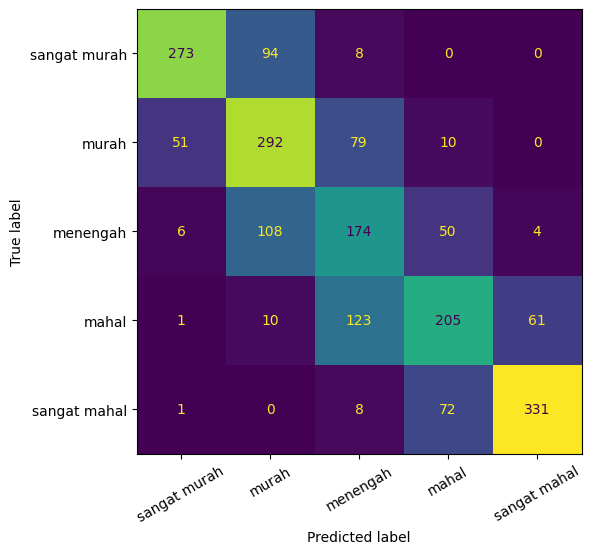

,Harga asli (Rp),Kelas aktual,Kelas prediksi
0,"3,500,000,000",murah,murah
1,"4,000,000,000",menengah,mahal
2,"16,500,000,000",sangat mahal,sangat mahal
3,"6,450,000,000",mahal,menengah
4,"10,000,000,000",mahal,mahal
5,"3,200,000,000",murah,menengah
6,"4,500,000,000",menengah,sangat mahal
7,"15,800,000,000",sangat mahal,sangat mahal
8,"2,350,000,000",murah,murah
9,"32,500,000,000",sangat mahal,sangat mahal


In [15]:
logits = model.predict(X_test_c, verbose=0)
y_pred = np.argmax(logits, axis=1)

print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=range(5)),
                       display_labels=class_names).plot(ax=ax, xticks_rotation=30, colorbar=False)
plt.tight_layout(); plt.show()

# Contoh 10 prediksi pertama
contoh = pd.DataFrame({
    "Harga asli (Rp)": test_df[TARGET].values[:10],
    "Kelas aktual": [class_names[i] for i in y_test[:10]],
    "Kelas prediksi": [class_names[i] for i in y_pred[:10]],
})
contoh.style.format({"Harga asli (Rp)": "{:,.0f}"})